# Q-learning en FrozenLake

## Aprendizaje por refuerzo en FrozenLake

El **aprendizaje por refuerzo** (*Reinforcement Learning*, RL) es un tipo de aprendizaje automático en el que un agente aprende a tomar decisiones interactuando con un entorno:

1. **Agente**: el que aprende (nuestro algoritmo de Q-learning)
2. **Entorno**: el mundo (la cuadrícula de FrozenLake)
3. **Estado**: la situación actual (posición en la cuadrícula)
4. **Acción**: lo que puede hacer el agente (moverse a la IZQUIERDA/ABAJO/DERECHA/ARRIBA)
5. **Recompensa**: el feedback del entorno (+1 por la meta, 0 en otro caso)
6. **Política**: la estrategia para elegir acciones

## Visión general del Q-learning

El **Q-learning** es un algoritmo de aprendizaje por refuerzo *sin modelo*:
- **Sin modelo** (*model-free*): no necesitamos conocer de antemano la dinámica del entorno
- ***Off-policy***: podemos aprender la política óptima mientras seguimos una política distinta (exploración)
- **Basado en valores**: aprendemos el valor de los pares estado-acción

## El proceso

1. **Inicializar**: crear una tabla Q (estados × acciones) llena de ceros. El agente no sabe nada al principio.
2. **Entrenar**: durante muchos episodios,
    1. empezar en el estado inicial;
    2. elegir una acción usando una **política épsilon-voraz** (explorar frente a explotar);
    3. tomar la acción, y observar la recompensa y el estado nuevo;
    4. **actualizar el valor Q** con: Q(s,a) ← Q(s,a) + α[r + γ·max Q(s',a') - Q(s,a)];
    5. repetir hasta que termine el episodio;
    6. reducir poco a poco la exploración (decaimiento de épsilon).
3. **Evaluar**: probar la política aprendida usando una **política voraz** (sin exploración), y medir su rendimiento (recompensa media).
4. **Usar el agente entrenado**: desplegarlo con la tabla Q aprendida, eligiendo siempre la acción con el valor Q más alto para cada estado.

El agente aprende por **prueba y error**, construyendo poco a poco el conocimiento de qué acciones llevan a la meta y cuáles al fracaso. ¡La tabla Q se convierte en una «chuleta» para moverse por el entorno de forma óptima!

## El entorno FrozenLake

[FrozenLake](https://gymnasium.farama.org/environments/toy_text/frozen_lake/) es uno de los entornos *toy-text* de [Gymnasium](https://gymnasium.farama.org/), la biblioteca estándar de entornos de aprendizaje por refuerzo. Su documentación lo describe así (traducido):

> El lago helado consiste en cruzar un lago helado desde el inicio hasta la meta sin caer en ningún agujero, caminando sobre el lago helado. Puede que el jugador no siempre se mueva en la dirección prevista, porque el lago helado resbala.
>
> El juego empieza con el jugador en la posición `[0,0]` del mundo de cuadrícula del lago helado, con la meta situada en el extremo opuesto del mundo, p. ej. `[3,3]` en el entorno de 4x4.
>
> Los agujeros del hielo están en posiciones fijas cuando se usa un mapa predeterminado, o en posiciones aleatorias cuando se genera un mapa aleatorio. Los mundos generados aleatoriamente siempre tienen un camino hasta la meta.
>
> El jugador se mueve hasta que llega a la meta o cae en un agujero.
>
> El lago resbala (salvo que se desactive), así que a veces el jugador puede moverse en perpendicular a la dirección prevista.

Creamos el lago con `is_slippery=False`: cada movimiento va adonde quiere el agente, así que el entorno es **determinista**.

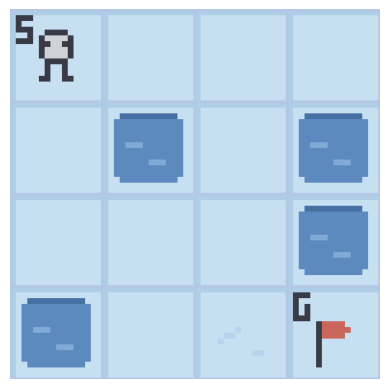

In [ ]:
import gymnasium as gym
import matplotlib.pyplot as plt

env = gym.make(
    'FrozenLake-v1',
    desc=None,
    map_name="4x4",
    is_slippery=False,  # Entorno determinista
    render_mode="rgb_array"  # Renderizado en el notebook
)

env.reset() # Reinicia el entorno

def show_env(env):
    '''Renderiza el entorno y lo muestra en el notebook.'''
    img = env.render()
    plt.imshow(img)
    plt.axis('off')
    plt.show()

show_env(env)

El entorno se creó con el mapa por defecto:

```python
desc=["SFFF","FHFH","FFFH","HFFG"]
```

<table border="1">
        <tr><td>S</td><td>F</td><td>F</td><td>F</td></tr>
        <tr><td>F</td><td>H</td><td>F</td><td>H</td></tr>
        <tr><td>F</td><td>F</td><td>F</td><td>H</td></tr>
        <tr><td>H</td><td>F</td><td>F</td><td>G</td></tr>
</table>
<p><b>S</b>=Inicio (<i>Start</i>), <b>F</b>=Helado (<i>Frozen</i>), <b>H</b>=Agujero (<i>Hole</i>), <b>G</b>=Meta (<i>Goal</i>)</p>

In [ ]:
print("Observation Space", env.observation_space)

Observation Space Discrete(16)


`Discrete(16)` significa que una observación es un único entero: la **posición actual del agente, calculada como `fila_actual * ncols + columna_actual`** (filas y columnas empiezan en 0).

Por ejemplo, la posición de la meta en el mapa de 4x4 es 3 * 4 + 3 = 15. El número de observaciones posibles depende del tamaño del mapa: **el mapa de 4x4 tiene 16 observaciones posibles.**

<table border="1">
  <tr><td>0</td><td>1</td><td>2</td><td>3</td></tr>
  <tr><td>4</td><td>5</td><td>6</td><td>7</td></tr>
  <tr><td>8</td><td>9</td><td>10</td><td>11</td></tr>
  <tr><td>12</td><td>13</td><td>14</td><td>15</td></tr>
</table>

In [ ]:
print("Action Space Shape", env.action_space)

Action Space Shape Discrete(4)


El espacio de acciones (el conjunto de acciones posibles que puede tomar el agente) es discreto, con 4 acciones disponibles 🎮:
- 0: IR A LA IZQUIERDA
- 1: IR ABAJO
- 2: IR A LA DERECHA
- 3: IR ARRIBA

Función de recompensa 💰:
- Llegar a la meta: +1
- Llegar a un agujero: 0
- Llegar a hielo: 0

Un agente que toma acciones aleatorias muestra cómo funciona el entorno, y por qué necesita aprender: casi todos los episodios acaban en un agujero.

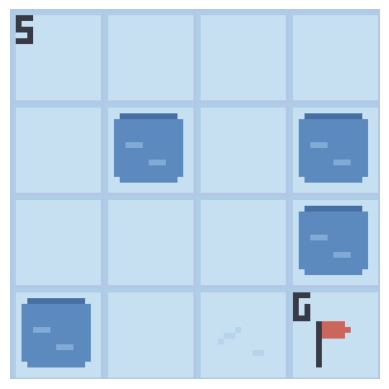

Episode 10, Step 6: State 1 --Action 1--> Next State 5, Reward: 0


Episode 10 finished in 6 steps.



In [ ]:
from IPython.display import clear_output
import time

for episode in range(10):
    state, info = env.reset()
    done = False
    step = 0
    print(f"Episode {episode + 1} starting...")

    # Muestra el estado inicial
    clear_output(wait=True)
    show_env(env)
    print(f"Episode {episode + 1}, Step {step}: State {state}")
    time.sleep(0.1)

    while not done:
        action = env.action_space.sample()  # Acción aleatoria
        next_state, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated
        step += 1

        # Limpia y muestra el entorno actualizado
        clear_output(wait=True)
        show_env(env)
        print(f"Episode {episode + 1}, Step {step}: State {state} --Action {action}--> Next State {next_state}, Reward: {reward}")

        state = next_state
        time.sleep(0.05)  # Pausa entre fotogramas

    print(f"Episode {episode + 1} finished in {step} steps.\n")
    time.sleep(1)  # Pausa entre episodios

## La tabla Q

In [ ]:
state_space = env.observation_space.n
print("There are ", state_space, " possible states")

action_space = env.action_space.n
print("There are ", action_space, " possible actions")

There are  16  possible states
There are  4  possible actions


In [ ]:
import numpy as np

# Una tabla Q de forma (state_space, action_space), con todos los valores inicializados a 0
def initialize_q_table(state_space, action_space):
    Qtable = np.zeros((state_space, action_space))
    return Qtable


Qtable_frozenlake = initialize_q_table(state_space, action_space)
Qtable_frozenlake

array([[0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.]])

### Entender la tabla Q

La tabla Q es una **tabla de consulta** que guarda la recompensa futura esperada de cada par estado-acción.

**Estructura**:
- **Filas**: estados (16 posiciones en la cuadrícula de 4×4)
- **Columnas**: acciones (4 movimientos posibles: IZQUIERDA, ABAJO, DERECHA, ARRIBA)
- **Valores**: Q(estado, acción) = recompensa futura esperada

**Inicialización**:
- Todos los valores empiezan en 0 (el agente no sabe nada)
- A medida que avanza el entrenamiento, los valores se actualizan para reflejar lo aprendido

**Ejemplo**:
- Q[6][1] = recompensa futura esperada si estamos en el estado 6 y tomamos la acción 1 (ABAJO)
- Las filas de los agujeros (5, 7, 11 y 12) y de la meta (15) siempre se quedan a 0: un episodio termina en cuanto el agente llega a uno de ellos, así que nunca toma una acción desde ahí
- El agente aprenderá qué acciones llevan a la meta (recompensa +1) y cuáles a los agujeros (recompensa 0)

## Las políticas 🤖

### El equilibrio entre exploración y explotación

En el aprendizaje por refuerzo, el agente se enfrenta a un reto fundamental:
- **Exploración**: probar acciones nuevas para descubrir estrategias que puedan ser mejores
- **Explotación**: usar las acciones que se sabe que son buenas para maximizar la recompensa

### Política voraz (explotación pura)

La política voraz (*greedy*) siempre elige la acción con el valor Q más alto para un estado dado.

In [ ]:
def greedy_policy(Qtable, state):
    """
    Política voraz: elige siempre la acción con el valor Q más alto.
    Se usa durante la EVALUACIÓN (sin exploración, explotación pura).

    Args:
        Qtable: la tabla Q con los valores aprendidos
        state: el estado actual

    Returns:
        action: la acción con el valor Q máximo para este estado
    """
    # Toma la acción con el valor más alto dado un estado
    action = np.argmax(Qtable[state])
    return action

### Política épsilon-voraz (exploración + explotación)

Épsilon-voraz (*epsilon-greedy*) es la **política de entrenamiento** que gestiona el equilibrio entre exploración y explotación.

La idea de épsilon-voraz:
- Con *probabilidad 1 - ɛ*: **explotamos** (elegimos la acción con el valor Q más alto, como greedy_policy)
- Con *probabilidad ɛ*: **exploramos** (probamos una acción aleatoria)

A medida que avanza el entrenamiento, **reducimos épsilon** poco a poco:
- Al principio del entrenamiento: ɛ alto (más exploración) → descubrir el entorno
- Al final del entrenamiento: ɛ bajo (más explotación) → afinar la estrategia aprendida

**Nota**: epsilon_greedy_policy incluye el comportamiento voraz cuando random_num > epsilon, ¡así que es una generalización de greedy_policy!

In [ ]:
import random

def epsilon_greedy_policy(Qtable, state, epsilon):
    """
    Política épsilon-voraz: equilibra exploración y explotación.
    Se usa durante el ENTRENAMIENTO.

    Args:
        Qtable: la tabla Q con los valores actuales
        state: el estado actual
        epsilon: probabilidad de exploración (de 0 a 1)

    Returns:
        action: o la mejor acción (explotación) o una acción aleatoria (exploración)
    """
    # Genera un número aleatorio entre 0 y 1
    random_num = random.uniform(0, 1)

    # Si random_num > epsilon --> EXPLOTACIÓN
    if random_num > epsilon:
        # Usa la política voraz (toma la acción con el valor Q más alto)
        action = greedy_policy(Qtable, state)
    # Si no --> EXPLORACIÓN
    else:
        # Toma una acción aleatoria para descubrir nuevas posibilidades
        action = env.action_space.sample()

    return action

La política voraz se usa **durante la evaluación**, cuando queremos probar lo que ha aprendido el agente sin ninguna aleatoriedad. Para entrenar, usamos épsilon-voraz para permitir la exploración.

## Los hiperparámetros explicados

Los hiperparámetros controlan cómo aprende el agente. Veamos cada uno:

### Parámetros de entrenamiento

- **n_training_episodes = 10.000**: cuántas partidas juega el agente mientras aprende
  - Más episodios = más aprendizaje, pero tarda más

- **learning_rate (α) = 0,7**: cuánto actualizamos los valores Q en cada paso
  - Alta (0,7-1,0): cada experiencia nueva sustituye la mayor parte de la estimación anterior. Rápida, y segura cuando una acción siempre tiene el mismo resultado, como en este lago; ruidosa cuando los resultados son aleatorios, como en un lago resbaladizo
  - Baja (0,1-0,3): cada estimación promedia muchas experiencias. Más lenta, pero estable cuando los resultados son aleatorios
  - Usamos 0,7 para un aprendizaje relativamente rápido

### Parámetros del entorno

- **gamma (γ) = 0,95**: factor de descuento de las recompensas futuras
  - Cerca de 1,0 (0,95): valora mucho las recompensas futuras (planifica)
  - Cerca de 0,0: solo le importan las recompensas inmediatas
  - FrozenLake necesita planificar, así que usamos 0,95


- **max_steps = 99**: pasos máximos por episodio
  - Evita bucles infinitos si el agente se atasca

### Parámetros de exploración (decaimiento de épsilon)

- **max_epsilon = 1,0**: empieza con un 100 % de exploración
  - ¡Al principio el agente no sabe nada, así que explora todo!

- **min_epsilon = 0,05**: termina con un 5 % de exploración
  - Incluso después de aprender, mantiene un 5 % de exploración para no atascarse

- **decay_rate = 0,0005**: lo rápido que baja épsilon
  - Controla la velocidad de la transición de la exploración a la explotación
  - Con 10.000 episodios y un decaimiento de 0,0005, épsilon baja de 1,0 a aproximadamente 0,056 en el último episodio: $0{,}05 + 0{,}95 \cdot e^{-0{,}0005 \cdot 9999} \approx 0{,}056$

### Parámetros de evaluación

- **n_eval_episodes = 100**: prueba el agente 100 veces
  - Más episodios dan más confianza estadística cuando los resultados son aleatorios (en este lago determinista, cada episodio de evaluación es la misma partida)

In [ ]:
# Parámetros de entrenamiento
n_training_episodes = 10000  # Total de episodios de entrenamiento
learning_rate = 0.7          # Tasa de aprendizaje

# Parámetros de evaluación
n_eval_episodes = 100        # Número total de episodios de prueba

# Parámetros del entorno
env_id = "FrozenLake-v1"     # Nombre del entorno
max_steps = 99               # Pasos máximos por episodio
gamma = 0.95                 # Tasa de descuento
eval_seed = []               # La semilla de evaluación del entorno

# Parámetros de exploración
epsilon = 1.0                 # Tasa de exploración
max_epsilon = 1.0             # Probabilidad de exploración al inicio
min_epsilon = 0.05            # Probabilidad mínima de exploración
decay_rate = 0.0005            # Tasa de decaimiento exponencial de la probabilidad de exploración

## El algoritmo de entrenamiento: Q-learning 📚

El **Q-learning** es un algoritmo de aprendizaje por refuerzo sin modelo que aprende el valor de tomar una acción en un estado concreto.

### La regla de actualización del Q-learning

El corazón del Q-learning es esta fórmula (el [notebook 2](bellman_equation.ipynb) la desarrolla a mano):

```
Q(s,a) ← Q(s,a) + α [R(s,a) + γ · max Q(s',a') - Q(s,a)]
```

Vamos a desglosarla:
- **Q(s,a)**: el valor Q actual para el estado s y la acción a
- **α (alfa)**: tasa de aprendizaje (cuánto actualizamos, de 0 a 1)
Si α = 0, no se aprende nada; si α = 1, adoptamos por completo la información nueva, ignorando la anterior.
- **R(s,a)**: la recompensa inmediata recibida después de tomar la acción a en el estado s
- **γ (gamma)**: factor de descuento (cuánto valoramos las recompensas futuras, de 0 a 1)
- **max Q(s',a')**: el valor Q máximo para el estado siguiente s' (el mejor valor futuro posible)
- **[R(s,a) + γ · max Q(s',a') - Q(s,a)]**: error de diferencia temporal (TD)

### ¿Qué significa esto?

1. **R(s,a)**: la recompensa inmediata que acabamos de obtener
2. **γ · max Q(s',a')**: la mejor recompensa futura posible (descontada)
3. **R(s,a) + γ · max Q(s',a')**: la recompensa total esperada (inmediata + futura)
4. **[...] - Q(s,a)**: la diferencia entre lo esperado y la estimación actual (el «error»)
5. **α × [error]**: el paso de actualización (no cambiamos el valor Q por completo, solo un poco)

Cuando el episodio termina en un agujero o en la meta, max Q(s',a') es 0: las filas de esos estados nunca cambian, porque el agente nunca actúa desde ellos, así que la actualización conserva solo la recompensa.

### Estructura del bucle de entrenamiento

1. **Bucle externo**: recorre los episodios de entrenamiento
   - Reduce épsilon (menos exploración con el tiempo)
   - Reinicia el entorno

2. **Bucle interno**: los pasos dentro de cada episodio
   - Elige una acción usando la política épsilon-voraz
   - Toma la acción y observa la recompensa y el estado siguiente
   - Actualiza la tabla Q con la fórmula del Q-learning
   - Si ha terminado (meta o agujero), finaliza el episodio
   - Pasa al estado siguiente

In [ ]:
def train(n_training_episodes, min_epsilon, max_epsilon, decay_rate, env, max_steps, Qtable):
    """
    Entrena al agente usando el algoritmo de Q-learning.

    Args:
        n_training_episodes: número total de episodios de entrenamiento
        min_epsilon: probabilidad mínima de exploración
        max_epsilon: probabilidad máxima de exploración
        decay_rate: ritmo al que decae épsilon
        env: el entorno de Gymnasium
        max_steps: pasos máximos por episodio
        Qtable: la tabla Q que hay que actualizar

    Returns:
        Qtable: la tabla Q actualizada después del entrenamiento
    """
    for episode in range(n_training_episodes):
        # Reduce épsilon (porque cada vez necesitamos menos exploración)
        # Decaimiento exponencial: empieza en max_epsilon y decae hacia min_epsilon
        epsilon = min_epsilon + (max_epsilon - min_epsilon) * np.exp(-decay_rate * episode)

        # Reinicia el entorno para empezar un episodio nuevo
        state, info = env.reset()  # Gymnasium devuelve (state, info)
        step = 0
        done = False

        # Repite hasta que termine el episodio (meta alcanzada, caída en un agujero o pasos máximos)
        for step in range(max_steps):
            # Elige una acción usando la política épsilon-voraz
            action = epsilon_greedy_policy(Qtable, state, epsilon)

            # Toma la acción y observa los resultados
            new_state, reward, terminated, truncated, info = env.step(action)
            done = terminated or truncated

            # Actualiza la tabla Q con la fórmula del Q-learning:
            # Q(s,a) ← Q(s,a) + α [R(s,a) + γ · max Q(s',a') - Q(s,a)]
            Qtable[state][action] = Qtable[state][action] + learning_rate * (
                reward + gamma * np.max(Qtable[new_state]) - Qtable[state][action]
            )

            # Si el episodio ha terminado, finaliza
            if done:
                break

            # Pasa al estado siguiente
            state = new_state

    return Qtable

In [ ]:
Qtable_frozenlake = train(n_training_episodes, min_epsilon, max_epsilon, decay_rate, env, max_steps, Qtable_frozenlake)

### ¡Entrenamiento completado! 🎉

Después del entrenamiento, la tabla Q contiene valores aprendidos en lugar de solo ceros.

**Qué esperar:**
- Algunos valores Q serán altos (positivos) → esos pares estado-acción llevan hacia la meta
- Algunos valores Q seguirán bajos o a cero → esos llevan a agujeros o callejones sin salida
- El patrón de valores Q representa el «conocimiento» que tiene el agente del entorno

**Nota**: un valor Q es la recompensa futura *descontada* esperada, no una probabilidad. La única recompensa aquí es +1 en la meta, así que en este lago determinista la mejor acción desde un estado a $k$ movimientos de la meta vale $\gamma^{k-1}$: 1 al lado de la meta, 0,95 a dos movimientos. El inicio está a seis movimientos, así que sus mejores acciones deberían valer alrededor de $0{,}95^5 \approx 0{,}77$:

In [ ]:
Qtable_frozenlake[0]

array([0.73509189, 0.77378094, 0.77378094, 0.73509189])

ABAJO y DERECHA empiezan ambas un camino más corto, y valen $0{,}95^5 \approx 0{,}774$. IZQUIERDA y ARRIBA chocan con el borde del lago y dejan al agente donde estaba: la misma posición, un movimiento después, así que valen $0{,}95 \times 0{,}774 \approx 0{,}735$.

## Evaluación 📊

Después del entrenamiento, tenemos que **evaluar** lo bien que ha aprendido nuestro agente.

### ¿Por qué separar entrenamiento y evaluación?

**Durante el entrenamiento** (con `epsilon_greedy_policy`):
- El agente explora al azar con probabilidad ε
- Esto ayuda a descubrir las estrategias óptimas
- El rendimiento no es representativo de lo que el agente «sabe»

**Durante la evaluación** (con `greedy_policy`):
- El agente usa solo las mejores acciones aprendidas (sin aleatoriedad)
- Esto muestra la calidad real de la política aprendida
- Queremos ver: «¿Qué haría el agente si solo usara lo que ha aprendido?»

### La diferencia clave

Esta es **exactamente la razón por la que necesitamos las dos funciones**:
- `epsilon_greedy_policy`: para aprender (entrenamiento)
- `greedy_policy`: para probar (evaluación)

La función `evaluate_agent`:
1. Ejecuta varios episodios usando **solo la política voraz**
2. Recoge las recompensas de cada episodio
3. Calcula la media y la desviación típica
4. Devuelve las métricas de rendimiento

In [ ]:
def evaluate_agent(env, max_steps, n_eval_episodes, Q, seed):
    """
    Evalúa el agente entrenado sin exploración.

    Esta función comprueba lo bien que ha aprendido el agente ejecutando episodios
    con la política VORAZ únicamente (sin exploración, explotación pura).

    Args:
        env: el entorno de Gymnasium
        max_steps: pasos máximos por episodio
        n_eval_episodes: número de episodios de evaluación
        Q: la tabla Q entrenada
        seed: semillas aleatorias para la reproducibilidad (opcional)

    Returns:
        mean_reward: recompensa media sobre todos los episodios de evaluación
        std_reward: desviación típica de las recompensas
    """
    episode_rewards = []

    for episode in range(n_eval_episodes):
        # Reinicia con semilla si se ha proporcionado; si no, al azar
        if seed:
            state, info = env.reset(seed=seed[episode])
        else:
            state, info = env.reset()

        step = 0
        done = False
        total_rewards_ep = 0

        for step in range(max_steps):
            # Usa la política VORAZ para evaluar (¡sin exploración!)
            # Por eso necesitamos la función greedy_policy aparte
            action = greedy_policy(Q, state)

            # Toma la acción
            new_state, reward, terminated, truncated, info = env.step(action)
            done = terminated or truncated

            total_rewards_ep += reward

            if done:
                break

            state = new_state

        episode_rewards.append(total_rewards_ep)

    mean_reward = np.mean(episode_rewards)
    std_reward = np.std(episode_rewards)

    return mean_reward, std_reward

In [ ]:
# Evaluamos nuestro agente
mean_reward, std_reward = evaluate_agent(env, max_steps, n_eval_episodes, Qtable_frozenlake, eval_seed)
print(f"Mean_reward={mean_reward:.2f} +/- {std_reward:.2f}")

Mean_reward=1.00 +/- 0.00


### Interpretación de los resultados

¡Rendimiento perfecto! 🎯

```
Mean_reward=1.00 +/- 0.00
```

**Qué significa:**
- **Recompensa media = 1,00**: el agente llegó a la meta en el 100 % de los episodios de evaluación (la recompensa de un episodio es 1 si llega a la meta y 0 si no, así que la recompensa media es la tasa de éxito)
- **Desviación típica = 0,00**: ninguna varianza, coherencia perfecta
- El agente ha aprendido una política que siempre llega a la meta en este lago determinista

Es lo esperado porque:
1. El entorno es determinista (`is_slippery=False`)
2. Entrenamos durante 10.000 episodios, suficientes para aprender la sencilla cuadrícula de 4×4
3. La tabla Q aprendida codifica ahora un camino del inicio a la meta

Un lago determinista y una política voraz también significan que los 100 episodios de evaluación son la misma partida jugada 100 veces, así que la desviación típica es 0 por construcción. En un lago resbaladizo (`is_slippery=True`), la misma evaluación estima con qué frecuencia llega el agente a la meta, y promediar muchos episodios es lo que hace fiable esa estimación.

## Visualizar el resultado

Hasta ahora hemos mirado números. Para ver al agente entrenado, jugamos un episodio con la política voraz, renderizamos cada paso como una imagen (con `render_mode="rgb_array"`, `env.render()` la devuelve como un array de píxeles) y unimos las imágenes en un GIF animado, a un fotograma por segundo.

In [ ]:
import io

from PIL import Image as PILImage


def record_gif(env, Qtable, fps=1):
    """
    Juega un episodio con la política voraz y lo devuelve como GIF animado, en bytes.
    """
    frames = []
    done = False

    state, info = env.reset()
    frames.append(env.render())

    while not done:
        # Toma la acción con el valor Q máximo (política voraz)
        action = greedy_policy(Qtable, state)
        state, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated
        frames.append(env.render())

    images = [PILImage.fromarray(frame) for frame in frames]
    gif_buffer = io.BytesIO()
    images[0].save(
        gif_buffer, format="GIF", save_all=True, append_images=images[1:], duration=1000 // fps, loop=0
    )
    return gif_buffer.getvalue()

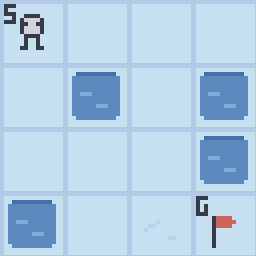

In [ ]:
from IPython.display import Image

Image(data=record_gif(env, Qtable_frozenlake, fps=1))

## Referencias

- Este notebook está adaptado de la Unidad 2 del [Hugging Face Deep RL Course](https://huggingface.co/learn/deep-rl-course/unit2/introduction) (licencia Apache 2.0).
- [Q-Learning From Scratch – Using Q Tables](https://www.youtube.com/watch?v=L-kQSpCJH4Q), un vídeo de Robert Cowher (en inglés).
- [An Introduction to Q-Learning: A Tutorial For Beginners](https://www.datacamp.com/tutorial/introduction-q-learning-beginner-tutorial) (DataCamp, en inglés).